In [1]:
import pandas as pd
from IPython.display import display

df = pd.read_excel("../data/Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
df.shape

(541909, 8)

In [3]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [5]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [6]:
df['CustomerID'].value_counts()

CustomerID
17841.0    7983
14911.0    5903
14096.0    5128
12748.0    4642
14606.0    2782
           ... 
18184.0       1
13256.0       1
13017.0       1
18174.0       1
15195.0       1
Name: count, Length: 4372, dtype: int64

In [7]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(5268)

в столбце Description есть 1454 пропуска,в столбце CustomerID есть 135080 пропусков.Всего в датафрейме 5268 дубликатов,по всем столбцам,не учитывая первый экземпляр.

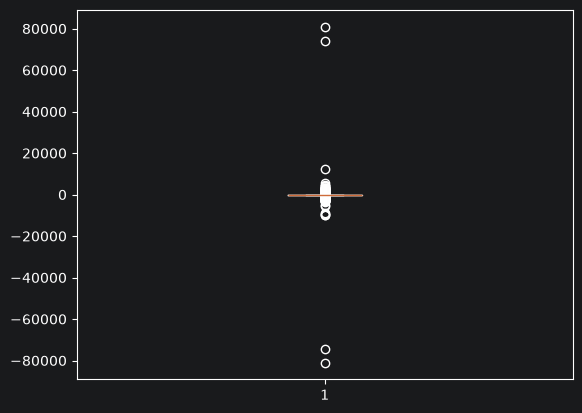

In [9]:
import matplotlib.pyplot as plt
plt.boxplot(df['Quantity'])
plt.show()

In [10]:
df_max_quintity = df.sort_values(by='Quantity',ascending=False).head()
df_max_quintity

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom
74614,542504,37413,NaN,5568,2011-01-28 12:03:00,0.00,NaN,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,2011-10-27 12:26:00,0.21,12901.0,United Kingdom


два первых значнени df_max_quintity сильно выбиваются от распределенися количества и на ящике с усами,они сильно похожи на выбросы,пока что удалить не будем.

In [11]:
df_min_quintity = df.sort_values(by='Quantity',ascending=True).head()
df_min_quintity

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
225529,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN,United Kingdom
225530,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,NaN,United Kingdom
4287,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,15838.0,United Kingdom


теперь видно что значения +-80995 и +-74215 это отмененные заказы,так как в столбце InvoiceNo есть буква C,что означает отмену заказа.

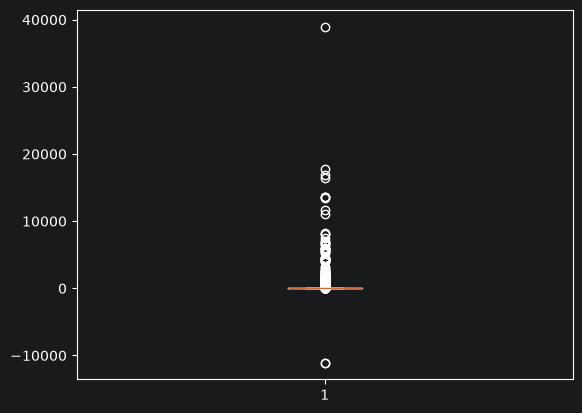

In [12]:
plt.boxplot(df['UnitPrice'])
plt.show()

In [13]:
df_max_unitprice = df.sort_values(by='UnitPrice',ascending=False).head(10)
df_max_unitprice

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom
524602,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom
43702,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom
43703,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom
16356,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,NaN,United Kingdom
15016,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom
16232,C537644,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:34:00,13474.79,NaN,United Kingdom
524601,C580604,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:35:00,11586.50,NaN,United Kingdom
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom


In [14]:
df_min_unitprice = df.sort_values(by='UnitPrice',ascending=True).head(10)
df_min_unitprice

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
40984,539750,22652,TRAVEL SEWING KIT,1,2010-12-21 15:40:00,0.00,NaN,United Kingdom
52217,540696,84562A,NaN,1,2011-01-11 09:14:00,0.00,NaN,United Kingdom
52262,540699,POST,NaN,1000,2011-01-11 09:32:00,0.00,NaN,United Kingdom
344867,567113,85215,Damaged,-29,2011-09-16 13:39:00,0.00,NaN,United Kingdom
204945,554696,85016,NaN,5,2011-05-25 17:14:00,0.00,NaN,United Kingdom
104419,545176,18098C,PORCELAIN BUTTERFLY OIL BURNER,6,2011-02-28 14:19:00,0.00,NaN,United Kingdom
104418,545176,20615,BLUE POLKADOT PASSPORT COVER,3,2011-02-28 14:19:00,0.00,NaN,United Kingdom
115488,546124,35610C,Thrown away.,-1121,2011-03-09 14:50:00,0.00,NaN,United Kingdom


в столбце UnitPrice есть сильные выбросы,нулевый и отрицательные значения,они могут объяснятбся ручным вводом,комиссией,бухгальтерской корректировкой,повреждениями и списаниями.далее проанализируем неположительные значения в столбце UnitPrice.и примем решения об удалении этих значений из датафрейма.


In [15]:
df_price_neg = df[df['UnitPrice'] < 0]
display(df_price_neg.head())
df_price_null = df[df['UnitPrice'] == 0]

df_price_null

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
536981,581234,72817,NaN,27,2011-12-08 10:33:00,0.0,NaN,United Kingdom
538504,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.0,NaN,United Kingdom
538505,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.0,NaN,United Kingdom
538554,581408,85175,NaN,20,2011-12-08 14:06:00,0.0,NaN,United Kingdom


In [16]:
print(df['UnitPrice'].shape[0], df_price_neg.shape[0], df_price_null.shape[0])


541909 2 2515


изучив 541909 значений unitprice видно,что 2 отрицательных значения связаны с корректировкой безнадежного долга,а 2515 нулевых связаны с как с проверкой,и пропусками в description,так и с другими значениями,которые надо выявить дальше.

In [17]:
df_price_null_desc_other = df[(df['UnitPrice'] ==0) & (df['Description']!='check') & (df['Description'].notna())]
df_price_null_desc_other

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
6391,536941,22734,amazon,20,2010-12-03 12:08:00,0.0,NaN,United Kingdom
6392,536942,22139,amazon,15,2010-12-03 12:08:00,0.0,NaN,United Kingdom
7313,537032,21275,?,-30,2010-12-03 16:50:00,0.0,NaN,United Kingdom
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
13264,537432,35833G,damages,-43,2010-12-06 16:10:00,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
535335,581212,22578,lost,-1050,2011-12-07 18:38:00,0.0,NaN,United Kingdom
536908,581226,23090,missing,-338,2011-12-08 09:56:00,0.0,NaN,United Kingdom
538504,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.0,NaN,United Kingdom
538505,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.0,NaN,United Kingdom


In [18]:
df_price_null_desc_other[df_price_null_desc_other['CustomerID'].notna()]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom


In [19]:
print(df_price_null[df_price_null['Description'] == 'check'].shape[0], df_price_null[df_price_null['Description'].isna()].shape[0])
print(df_price_null_desc_other.shape[0], df_price_null_desc_other[df_price_null_desc_other['CustomerID'].notna()].shape[0])
print((df_price_null_desc_other.shape[0]- df_price_null_desc_other[df_price_null_desc_other['CustomerID'].notna()].shape[0])/df_price_null_desc_other.shape[0] *100)

159 1454
902 40
95.56541019955654


Можно заметить что из 2515 нулевых значений unitprice,1454 строки с нулевой ценой и пропущенным описание, 159 описание равно 'check'.В остальных 902 значениях unitprice равен нулю,но description не является пропуском и не равны check.Из этих 902 значений 40 значений имеют customerId,а остальные 862 значений не имеют customerId,то есть среди этих 902 строк у 95.57% отсутсвует CustomerID.

In [20]:
print(f"начало периода {df['InvoiceDate'].min()}, конец периода {df['InvoiceDate'].max()}")
print(f"число уникальных заказов,включая отмененные {df['InvoiceNo'].nunique()}, число уникальных товаров {df['StockCode'].nunique()}")
print(f"число уникальных известных покупателей {df['CustomerID'].nunique()}, число уникальных  стран {df['Country'].nunique()}")
print(f"число строк с отрицательным значением Quantity {df[df['Quantity'] < 0].shape[0]}, число строк с нулевым значением Quantity {df[df['Quantity'] == 0].shape[0]}")
print(f"число строк с префиксом C {df[df['InvoiceNo'].astype('string').str.startswith('C')].shape[0]}")
A =  df['Quantity'] < 0
B = df['InvoiceNo'].astype('string').str.startswith('C')
display(pd.crosstab(A,B))
print("префикс C в InvoiceNo встречается только в строках с отрицательным значением Quantity,но не каждое отрицательное значение Quantity имеет префикс C в InvoiceNo,")
display(df[A & ~B])
print('в 1336 строках с отрицательным значением Quantity и без префикса C в InvoiceNo,во всех CustomerID отсутсвует,country равна united kingdom,а в description 64.5% строк пропущены')
df['Country'].value_counts()


начало периода 2010-12-01 08:26:00, конец периода 2011-12-09 12:50:00
число уникальных заказов,включая отмененные 25900, число уникальных товаров 4070
число уникальных известных покупателей 4372, число уникальных  стран 38
число строк с отрицательным значением Quantity 10624, число строк с нулевым значением Quantity 0
число строк с префиксом C 9288


InvoiceNo,False,True
Quantity,,
False,531285,0
True,1336,9288


префикс C в InvoiceNo встречается только в строках с отрицательным значением Quantity,но не каждое отрицательное значение Quantity имеет префикс C в InvoiceNo,


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
535333,581210,23395,check,-26,2011-12-07 18:36:00,0.0,NaN,United Kingdom
535335,581212,22578,lost,-1050,2011-12-07 18:38:00,0.0,NaN,United Kingdom
535336,581213,22576,check,-30,2011-12-07 18:38:00,0.0,NaN,United Kingdom
536908,581226,23090,missing,-338,2011-12-08 09:56:00,0.0,NaN,United Kingdom


в 1336 строках с отрицательным значением Quantity и без префикса C в InvoiceNo,во всех CustomerID отсутсвует,country равна united kingdom,а в description 64.5% строк пропущены


Country
United Kingdom          495478
Germany                   9495
France                    8557
EIRE                      8196
Spain                     2533
Netherlands               2371
Belgium                   2069
Switzerland               2002
Portugal                  1519
Australia                 1259
Norway                    1086
Italy                      803
Channel Islands            758
Finland                    695
Cyprus                     622
Sweden                     462
Unspecified                446
Austria                    401
Denmark                    389
Japan                      358
Poland                     341
Israel                     297
USA                        291
Hong Kong                  288
Singapore                  229
Iceland                    182
Canada                     151
Greece                     146
Malta                      127
United Arab Emirates        68
European Community          61
RSA                         58


## Итоги первичного изучения данных

### Структура и охват

Датасет содержит 541 909 строк и 8 столбцов. Одна строка соответствует товарной позиции, а не отдельному заказу.

Период наблюдений: с 1 декабря 2010 года, 08:26, по 9 декабря 2011 года, 12:50. Декабрь 2011 года представлен не полностью, что необходимо учитывать при сравнении месяцев.

Обнаружено:
- 25 900 уникальных номеров счетов, включая отменённые и служебные операции;
- 4070 уникальных кодов StockCode, среди которых есть служебные коды;
- 4372 уникальных известных покупателя;
- 38 различных значений Country, включая Unspecified и European Community.

Больше всего строк относится к United Kingdom — 495 478. Это количество товарных позиций, а не заказов или покупателей.

### Типы данных, пропуски и дубликаты

InvoiceDate уже имеет тип даты и времени. CustomerID хранится как число, но является идентификатором: его среднее и стандартное отклонение не характеризуют покупательское поведение.

В Description отсутствуют 1454 значения, в CustomerID — 135 080. В остальных столбцах пропусков не обнаружено.

Найдено 5268 полных повторов строк после первого экземпляра. Совпадение значений всех столбцов само по себе ещё не доказывает ошибку регистрации операции.

### Необычные количества и отмены

Отрицательное Quantity встречается в 10 624 строках. Нулевых количеств нет.

| Quantity | Без префикса C | С префиксом C |
|---|---:|---:|
| Неотрицательное | 531 285 | 0 |
| Отрицательное | 1336 | 9288 |

Все строки с префиксом C имеют отрицательное количество. Однако отрицательное количество встречается и без этого префикса.

Среди 1336 таких строк:
- во всех отсутствует CustomerID;
- во всех Country равно United Kingdom;
- во всех UnitPrice равно нулю;
- в 862 строках (64,52%) отсутствует Description.

Некоторые описания указывают на возможные списания, потери или проверки остатков. Назначение этих операций требует уточнения.

Для крупных положительных количеств 80 995 и 74 215 найдены соответствующие отрицательные записи с префиксом C. Совпадение товара, покупателя и цены, а также близкое время операций указывают на вероятную отмену этих покупок.

### Необычные цены

В UnitPrice обнаружены 2 отрицательных значения. Обе строки имеют описание Adjust bad debt, указывающее на корректировку безнадёжного долга.

Нулевая цена встречается в 2515 строках:
- в 1454 отсутствует Description;
- в 159 Description точно равно 'check';
- в остальных 902 описание заполнено и отличается от 'check'.

Среди последних 902 строк CustomerID отсутствует в 862 случаях (95,57%). Это совместное наличие признаков, а не объяснение причины нулевой цены.

Среди наиболее высоких цен встречаются AMAZON FEE, Manual и Adjust bad debt. Следовательно, некоторые крайние суммы относятся к служебным или бухгалтерским записям. Большое значение само по себе не является доказательством ошибки.

### Следующий этап

На следующем этапе определим, какие записи подходят для анализа покупок и как обработать обнаруженные проблемы.
